# Giá trị và chiến dịch

Tính lại chiến dịch bằng cùng hàm dashboard. Save rate là giả định; kết quả không nhân quả.

Chạy `python -m telco_retention run-all` trước. Notebook sử dụng artifacts và logic của package, không có mô hình thứ hai độc lập.

In [1]:
from telco_retention.common import ROOT, latest_run, read_json
import pandas as pd
from IPython.display import display, Image
run = latest_run()
print('Run:', run.name)

Run: 20261003T183647103688Z-88be4b93


In [2]:
from telco_retention.business import campaign
from telco_retention.analysis import default_budget
cfg = read_json(run / 'manifest.json')['config']
scores = pd.read_csv(run / 'scorecard.csv').query("split == 'test'")
target, summary = campaign(scores, default_budget(len(scores), cfg), cfg, thresholds=read_json(run / 'targeting_thresholds.json'))
display({k:v for k,v in summary.items() if k != 'scenario'})
display(target.loc[target.selected].head(10))

{'selected_count': 140,
 'cost': 3080.0,
 'remaining_budget': 0.0,
 'expected_saved': 17.330155696918357,
 'expected_retained_value': 5939.215271780773,
 'expected_net_value': 2859.2152717807726,
 'roi': 0.928316646682069,
 'precision_contacted': 0.6071428571428571,
 'label_based_simulated_net': 2708.6110000000003,
 'high_risk_high_value_coverage': 0.9803921568627451,
 'scenario_id': '765d0287b0f6',
 'solver': {'status': 'optimal_sort', 'gap': 0.0}}

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,total_cost,expected_saved_probability,expected_retained_value,expected_net_value,break_even_save_rate,break_even_total_cost,selected,selection_reason,decision_detail,scenario_id
20,0196-VULGZ,Female,1,Yes,No,6,Yes,Yes,Fiber optic,No,...,22.0,0.161924,36.877376,14.877376,0.119314,36.877376,True,Được ưu tiên theo chiến lược ev,p=81.0% × q=20.0% × V=227.74 − chi phí 22.00 =...,765d0287b0f6
32,0295-PPHDO,Male,0,No,No,1,Yes,Yes,Fiber optic,No,...,22.0,0.170255,43.877300,21.877300,0.100280,43.877300,True,Được ưu tiên theo chiến lược ev,p=85.1% × q=20.0% × V=257.72 − chi phí 22.00 =...,765d0287b0f6
36,0311-UNPFF,Female,0,No,No,26,Yes,No,Fiber optic,No,...,22.0,0.096506,38.563933,16.563933,0.114096,38.563933,True,Được ưu tiên theo chiến lược ev,p=48.3% × q=20.0% × V=399.60 − chi phí 22.00 =...,765d0287b0f6
39,0324-BRPCJ,Female,1,Yes,No,68,Yes,Yes,Fiber optic,No,...,22.0,0.090859,40.968169,18.968169,0.107400,40.968169,True,Được ưu tiên theo chiến lược ev,p=45.4% × q=20.0% × V=450.90 − chi phí 22.00 =...,765d0287b0f6
44,0337-CNPZE,Female,0,No,No,41,Yes,Yes,Fiber optic,No,...,22.0,0.116940,55.938475,33.938475,0.078658,55.938475,True,Được ưu tiên theo chiến lược ev,p=58.5% × q=20.0% × V=478.35 − chi phí 22.00 =...,765d0287b0f6
63,0434-CSFON,Female,0,Yes,No,47,Yes,Yes,Fiber optic,No,...,22.0,0.118297,53.499945,31.499945,0.082243,53.499945,True,Được ưu tiên theo chiến lược ev,p=59.1% × q=20.0% × V=452.25 − chi phí 22.00 =...,765d0287b0f6
89,0576-WNXXC,Male,1,Yes,No,27,Yes,Yes,Fiber optic,No,...,22.0,0.117298,50.435400,28.435400,0.087240,50.435400,True,Được ưu tiên theo chiến lược ev,p=58.6% × q=20.0% × V=429.97 − chi phí 22.00 =...,765d0287b0f6
94,0637-YLETY,Female,0,No,No,16,Yes,Yes,Fiber optic,No,...,22.0,0.107800,37.100400,15.100400,0.118597,37.100400,True,Được ưu tiên theo chiến lược ev,p=53.9% × q=20.0% × V=344.16 − chi phí 22.00 =...,765d0287b0f6
100,0684-AOSIH,Male,0,Yes,No,1,Yes,No,Fiber optic,Yes,...,22.0,0.147523,37.839744,15.839744,0.116280,37.839744,True,Được ưu tiên theo chiến lược ev,p=73.8% × q=20.0% × V=256.50 − chi phí 22.00 =...,765d0287b0f6
102,0702-PGIBZ,Male,0,No,Yes,4,Yes,Yes,Fiber optic,No,...,22.0,0.156415,42.949894,20.949894,0.102445,42.949894,True,Được ưu tiên theo chiến lược ev,p=78.2% × q=20.0% × V=274.59 − chi phí 22.00 =...,765d0287b0f6


In [3]:
display(pd.read_csv(run / 'strategy_comparison.csv'))
display(read_json(run / 'segment_policy.json'))

,strategy,selected_count,cost,remaining_budget,expected_saved,expected_retained_value,expected_net_value,roi,precision_contacted,label_based_simulated_net,high_risk_high_value_coverage,scenario_id,solver_status
0,none,0.0,0.0,3080.0,0.000000,0.000000,0.000000,NaN,NaN,0.00000,0.000000,68bd2436646f,empty
1,risk,140.0,3080.0,0.0,20.750204,4789.331842,1709.331842,0.554978,0.700000,1370.28400,0.039216,0c4f7b8db8b1,baseline
2,risk_positive_ev,140.0,3080.0,0.0,20.705880,4872.562145,1792.562145,0.582001,0.678571,1347.30700,0.039216,777587bedd0e,baseline
3,value,140.0,3080.0,0.0,5.820465,2767.371360,-312.628640,-0.101503,0.285714,743.15500,0.294118,ca74cda36346,baseline
4,ev,140.0,3080.0,0.0,17.330156,5939.215272,2859.215272,0.928317,0.607143,2708.61100,0.980392,765d0287b0f6,optimal_sort
5,multi_offer,140.0,3080.0,0.0,17.330156,5939.215272,2859.215272,0.928317,0.607143,2708.61100,0.980392,2fb0a8947bbc,optimal
6,random_mean,140.0,3080.0,0.0,7.505314,1933.895235,-1146.104765,-0.372112,0.261786,-1171.18388,0.102353,NaN,100 seeded random campaigns
7,segment_policy,140.0,3080.0,0.0,17.330156,5939.215272,2859.215272,0.928317,0.607143,2708.61100,0.980392,16b3469349dd,optimal_sort


{'policy': {'new': 'standard', 'developing': 'standard', 'loyal': 'standard'},
 'chosen_on': 'validation',
 'validation_budget': 3080.0}

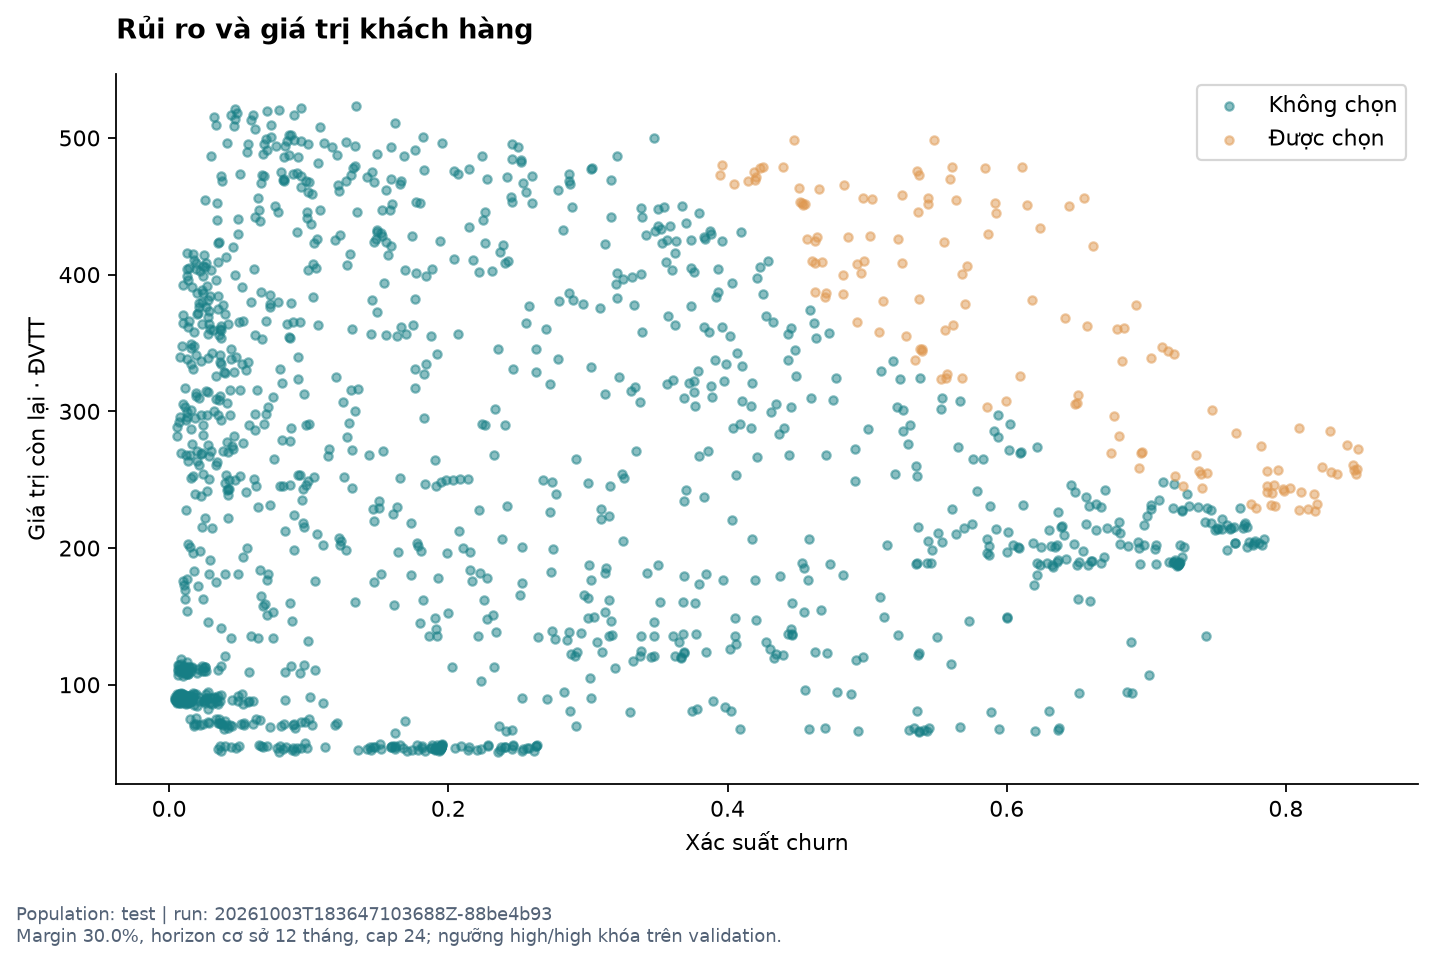

In [4]:
display(Image(filename=str(ROOT / 'reports/figures/risk_value.png')))